> **Методологическое уточнение.** Этот ноутбук сохраняет исторический эксперимент. Результаты дообучения получены после просмотра теста: это исследовательские оценки, не независимое подтверждение. Исправленное сравнение и границы выводов: [ноутбук 10](10_methodology_audit.ipynb), [аудит](METHODOLOGY_REVIEW.md).

# 07 — Локальная проверка заранее подготовленного резерва

Веса не дообучаются и не меняются. Меняется режим запуска. Ноль перегрузок после подготовки не означает ноль во время самой подготовки. Публикация на GitHub не выполнялась.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from operational_start import study
# Готовые результаты. Для повторения: study(Path.cwd(), 'results/operational_start')
display(pd.Series(json.loads(Path('results/operational_start/protocol.json').read_text())))
display(pd.read_csv('results/operational_start/validation.csv'))
summary=pd.read_csv('results/operational_start/comparison.csv',index_col=0)
display(summary)

purpose                Causal initial reserve only, no new training a...
candidate_margins                                   [1.0, 0.9, 0.8, 0.7]
history_slots                                                          4
decision_lead_slots                                                    6
selection              validation overloaded slots, excess requests, ...
weights_sha256         2b6e6b32dce3a3d2becffd9b1cb5486d0ecd29bc05372f...
test_note              Previously observed test, repeated diagnostic ...
preparation_note       Decision uses only requests before t=start-6. ...
dtype: object

,margin,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes,initial_shards,preparation_minutes,preparation_cost,preparation_overloaded_slots,preparation_excess_requests,total_with_preparation
0,1.0,1193.332274,739.0,447.720466,6.611808,64,121086,34.193734,7.697917,13,7,90,62.209447,4,6845,1255.541721
1,0.9,1192.710194,739.0,447.720466,5.989728,64,121086,30.976577,7.697917,12,8,90,63.758542,4,6845,1256.468736
2,0.8,1192.710194,739.0,447.720466,5.989728,64,121086,30.976577,7.697917,12,8,90,63.758542,4,6845,1256.468736
3,0.7,1192.710194,739.0,447.720466,5.989728,64,121086,30.976577,7.697917,12,8,90,63.758542,4,6845,1256.468736


,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes,initial_shards,preparation_minutes,preparation_cost,preparation_overloaded_slots,preparation_excess_requests,total_with_preparation
strategy,,,,,,,,,,,,,,,
safety_dqn_cold,889.648951,854.0,9.609909,26.039042,2,2599,134.663934,4.447917,31,2,0,0.000000,0,0,889.648951
safety_dqn_reserve,887.422861,863.0,0.000000,24.422861,0,0,126.305666,4.494792,31,8,90,116.715548,6,21095,1004.138408
threshold_same_reserve,1028.484926,1018.0,6.326493,4.158433,2,1711,21.505820,5.302083,6,8,90,116.715548,6,21095,1145.200473
fixed_6,1153.438344,1152.0,1.438344,0.000000,2,389,0.000000,6.000000,0,6,90,114.681065,6,21688,1268.119409
fixed_7,1344.000000,1344.0,0.000000,0.000000,0,0,0.000000,7.000000,0,7,90,115.644521,6,21229,1459.644521
fixed_8,1536.000000,1536.0,0.000000,0.000000,0,0,0.000000,8.000000,0,8,90,116.715548,6,21095,1652.715548


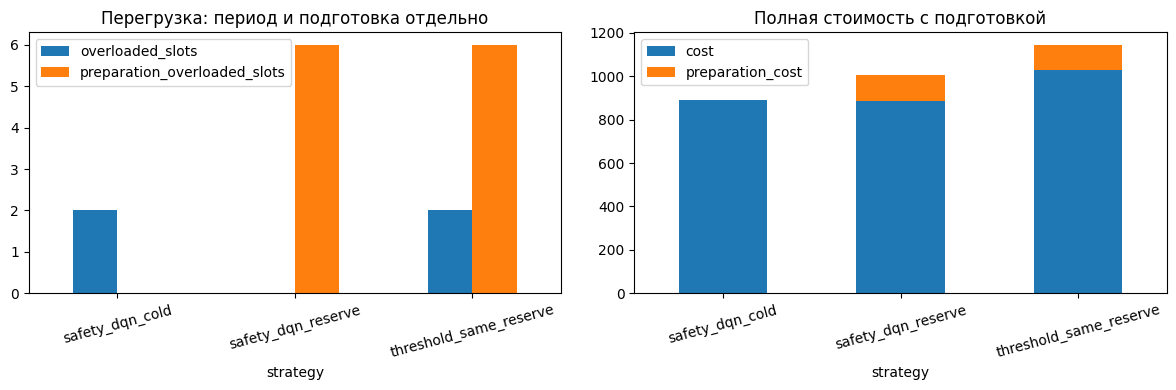

In [2]:
names=['safety_dqn_cold','safety_dqn_reserve','threshold_same_reserve']
fig,axes=plt.subplots(1,2,figsize=(12,4))
summary.loc[names,['overloaded_slots','preparation_overloaded_slots']].plot.bar(ax=axes[0],rot=15,title='Перегрузка: период и подготовка отдельно')
summary.loc[names,['cost','preparation_cost']].plot.bar(stacked=True,ax=axes[1],rot=15,title='Полная стоимость с подготовкой')
fig.tight_layout();fig.savefig('results/operational_start/comparison.png',dpi=150);plt.show()

Вывод: на оцениваемых 48 часах получилось 0 превышений, но на подготовке — 6. Нельзя называть систему идеальной или сравнивать только бесплатный резерв с прежним стартом. Для исключения перегрузки целиком необходимо изменить ограничения системы, а не просто добавить эпохи обучения.